# 3. Initial forecasting

## Fixed time-based train/test split

## SARIMA and residual diagnostics

## Prophet with weekly, yearly, and French holiday seasonality

## Metrics and forecast comparison

# 3. Initial forecasting

Paris PM2.5, daily means, 2023-01-01 to 2025-10-30 (1034 days, 20 isolated missing days filled by linear interpolation).

**Plan**
1. Fixed chronological split shared with the team (last 90 days = test).
2. Stationarity tests and ACF/PACF on the training set only.
3. ARIMA/SARIMA order search (AIC/BIC), residual diagnostics.
4. Prophet with weekly, yearly and French holiday effects.
5. Comparison with RMSE/MAE (AIC/BIC for ARIMA/SARIMA), against simple baselines and on a rolling-origin evaluation.

## 1. Setup and train/test split

The split comes from `src.load_data.get_train_test` (last 90 days held out). All model selection is done on the training set only. The test period (Aug-Oct 2025) is a low-pollution season, with a mean of about 7.8 µg/m³ against 11.1 in the training set.

Full series: 2023-01-01 -> 2025-10-30 (1034 days)
Train: 2023-01-01 -> 2025-08-01 (944 days)
Test:  2025-08-02 -> 2025-10-30 (90 days)
Remaining NaNs: 0


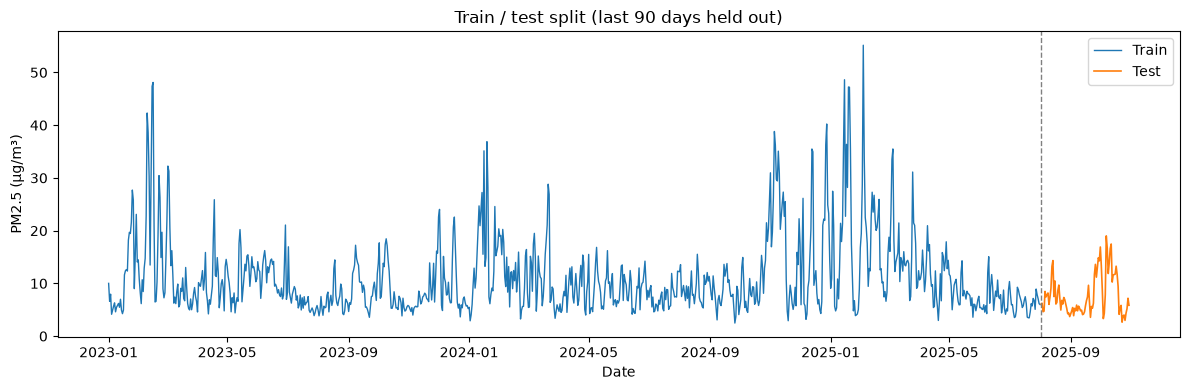

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))
os.chdir(project_root)

from src.eda import impute_linear
from src.load_data import get_train_test, load_daily_series
from src.plots import save_current_figure

DATA_PATH = project_root / "data/processed/pm25_paris_daily.csv"
(project_root / "reports/figures").mkdir(parents=True, exist_ok=True)

TEST_DAYS = 90  # shared split defined in src.load_data.get_train_test

# Same preprocessing as the EDA notebook: daily calendar + linear interpolation
series = impute_linear(load_daily_series(DATA_PATH))
train, test = get_train_test(series, test_days=TEST_DAYS)

print(f"Full series: {series.index.min().date()} -> {series.index.max().date()} ({len(series)} days)")
print(f"Train: {train.index.min().date()} -> {train.index.max().date()} ({len(train)} days)")
print(f"Test:  {test.index.min().date()} -> {test.index.max().date()} ({len(test)} days)")
print(f"Remaining NaNs: {series.isna().sum()}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train.index, train.values, label="Train", linewidth=1)
ax.plot(test.index, test.values, label="Test", linewidth=1.2, color="tab:orange")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=1)
ax.set_title("Train / test split (last 90 days held out)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Date")
ax.legend()
fig.tight_layout()
save_current_figure("03_train_test_split.png")
plt.show()

## 2. Stationarity tests (training set)

ADF (H0: unit root) and KPSS (H0: stationary) are run on the raw series and on its differenced versions. Both tests agree that the raw series is stationary, so `d = 0` is the starting point.

In [2]:
import warnings

from statsmodels.tsa.stattools import adfuller, kpss


def stationarity_row(x: pd.Series, label: str) -> dict:
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # FutureWarning (adfuller) / InterpolationWarning (kpss)
        adf_stat, adf_p, adf_lag, *_ = adfuller(x, autolag="AIC")
        kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    return {
        "series": label,
        "n_obs": len(x),
        "adf_stat": round(adf_stat, 3),
        "adf_pvalue": round(adf_p, 4),
        "adf_lags": adf_lag,
        "kpss_stat": round(kpss_stat, 3),
        "kpss_pvalue": round(kpss_p, 4),  # reported value is clipped to [0.01, 0.10]
        "adf_says_stationary": adf_p < 0.05,
        "kpss_says_stationary": kpss_p > 0.05,
    }


candidates = {
    "raw (d=0, D=0)": train,
    "diff 1 (d=1, D=0)": train.diff(),
    "seasonal diff 7 (d=0, D=1)": train.diff(7),
    "diff 1 + seasonal diff 7 (d=1, D=1)": train.diff().diff(7),
}

stationarity = pd.DataFrame([stationarity_row(x, label) for label, x in candidates.items()])
stationarity.set_index("series")

,n_obs,adf_stat,adf_pvalue,adf_lags,kpss_stat,kpss_pvalue,adf_says_stationary,kpss_says_stationary
series,,,,,,,,
"raw (d=0, D=0)",944,-4.244,0.0006,14,0.262,0.1,True,True
"diff 1 (d=1, D=0)",943,-11.231,0.0000,18,0.025,0.1,True,True
"seasonal diff 7 (d=0, D=1)",937,-7.781,0.0000,21,0.020,0.1,True,True
"diff 1 + seasonal diff 7 (d=1, D=1)",936,-13.893,0.0000,20,0.012,0.1,True,True


## 3. ACF / PACF

- Raw series: the PACF cuts off after lag 1-3, suggesting an AR component of order 1 to 3. There is no clear weekly pattern (ACF at lag 7 is about 0.21).
- After a seasonal difference (D=1, s=7), the ACF shows a spike of about -0.54 at lag 7. This is the signature of over-differencing, not of genuine weekly seasonality.

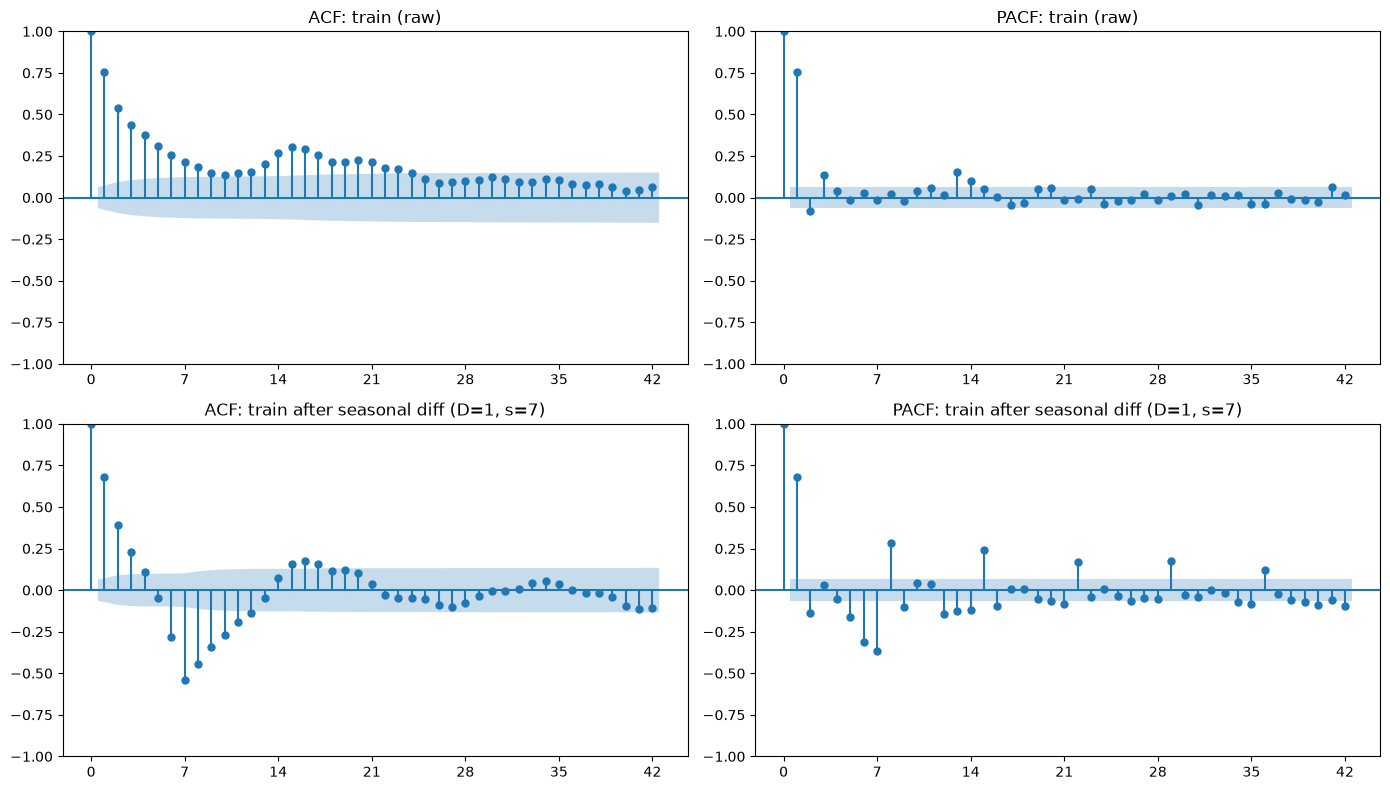

,ACF raw,PACF raw,ACF D=1,PACF D=1
lag,,,,
1,0.758,0.758,0.682,0.682
2,0.539,-0.083,0.392,-0.135
3,0.437,0.136,0.228,0.032
7,0.213,-0.014,-0.538,-0.368
14,0.269,0.097,0.075,-0.121
21,0.213,-0.016,0.040,-0.084
28,0.100,-0.014,-0.079,-0.051


In [3]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

LAGS = 42  # covers seasonal lags 7, 14, 21, 28, 35, 42

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(train, lags=LAGS, ax=axes[0, 0])
axes[0, 0].set_title("ACF: train (raw)")
plot_pacf(train, lags=LAGS, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF: train (raw)")

train_sdiff = train.diff(7).dropna()
plot_acf(train_sdiff, lags=LAGS, ax=axes[1, 0])
axes[1, 0].set_title("ACF: train after seasonal diff (D=1, s=7)")
plot_pacf(train_sdiff, lags=LAGS, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF: train after seasonal diff (D=1, s=7)")

for ax in axes.ravel():
    ax.set_xticks(range(0, LAGS + 1, 7))  # tick every 7 lags to spot weekly structure

fig.tight_layout()
save_current_figure("03_train_acf_pacf.png")
plt.show()

# Numeric values at key lags
key_lags = [1, 2, 3, 7, 14, 21, 28]
acf_raw = acf(train, nlags=max(key_lags))
pacf_raw = pacf(train, nlags=max(key_lags), method="ywm")
acf_sd = acf(train_sdiff, nlags=max(key_lags))
pacf_sd = pacf(train_sdiff, nlags=max(key_lags), method="ywm")

pd.DataFrame(
    {
        "ACF raw": acf_raw[key_lags],
        "PACF raw": pacf_raw[key_lags],
        "ACF D=1": acf_sd[key_lags],
        "PACF D=1": pacf_sd[key_lags],
    },
    index=pd.Index(key_lags, name="lag"),
).round(3)

## 4. Exploratory SARIMA grid (stationarity and invertibility constraints OFF)

A first, fast grid over `p, q, P, Q, D` with `d = 0`. The `D = 1` models appear to win on AIC/BIC (about 5531 vs 5548), but this grid disables the invertibility constraint, so the result is not trustworthy. It is kept as a documented exploratory step.

In [4]:
import itertools
import time

from statsmodels.tsa.statespace.sarimax import SARIMAX

S = 7
grid = list(itertools.product(range(0, 4), range(0, 3), range(0, 2), range(0, 2), [0, 1]))
rows = []
t0 = time.time()

for i, (p, q, P, Q, D) in enumerate(grid, start=1):
    order = (p, 0, q)
    seasonal_order = (P, D, Q, S)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = SARIMAX(
                train,
                order=order,
                seasonal_order=seasonal_order,
                trend="c" if D == 0 else None,
                enforce_stationarity=False,
                enforce_invertibility=False,
            )
            res = model.fit(disp=False, maxiter=200)
        rows.append(
            {
                "order": order,
                "seasonal_order": seasonal_order,
                "D": D,
                "aic": res.aic,
                "bic": res.bic,
                "converged": bool(res.mle_retvals.get("converged", False)),
            }
        )
    except Exception as exc:
        rows.append(
            {"order": order, "seasonal_order": seasonal_order, "D": D,
             "aic": np.nan, "bic": np.nan, "converged": False}
        )
    if i % 20 == 0:
        print(f"{i}/{len(grid)} models fitted ({time.time() - t0:.0f}s)")

grid_results = pd.DataFrame(rows).dropna(subset=["aic"])
print(f"Done: {len(grid_results)} models fitted, {time.time() - t0:.0f}s total")
print(f"Non-converged: {(~grid_results['converged']).sum()}")

# Rank within each D (AIC/BIC are not strictly comparable across different D)
for D in (0, 1):
    sub = grid_results[(grid_results["D"] == D) & grid_results["converged"]]
    print(f"\n=== Top 5 by AIC, D={D} ===")
    display(sub.sort_values("aic").head(5).round(2))
    print(f"=== Top 5 by BIC, D={D} ===")
    display(sub.sort_values("bic").head(5).round(2))

20/96 models fitted (9s)
40/96 models fitted (24s)
60/96 models fitted (49s)
80/96 models fitted (117s)
Done: 96 models fitted, 193s total
Non-converged: 2

=== Top 5 by AIC, D=0 ===


,order,seasonal_order,D,aic,bic,converged
66,"(2, 0, 2)","(0, 0, 1, 7)",0,5547.67,5581.54,True
70,"(2, 0, 2)","(1, 0, 1, 7)",0,5548.59,5587.31,True
92,"(3, 0, 2)","(1, 0, 0, 7)",0,5548.79,5587.51,True
94,"(3, 0, 2)","(1, 0, 1, 7)",0,5550.75,5594.31,True
76,"(3, 0, 0)","(1, 0, 0, 7)",0,5551.78,5580.82,True


=== Top 5 by BIC, D=0 ===


,order,seasonal_order,D,aic,bic,converged
76,"(3, 0, 0)","(1, 0, 0, 7)",0,5551.78,5580.82,True
66,"(2, 0, 2)","(0, 0, 1, 7)",0,5547.67,5581.54,True
42,"(1, 0, 2)","(0, 0, 1, 7)",0,5554.25,5583.29,True
84,"(3, 0, 1)","(1, 0, 0, 7)",0,5552.23,5586.11,True
68,"(2, 0, 2)","(1, 0, 0, 7)",0,5552.98,5586.87,True



=== Top 5 by AIC, D=1 ===


,order,seasonal_order,D,aic,bic,converged
67,"(2, 0, 2)","(0, 1, 1, 7)",1,5531.04,5560.03,True
71,"(2, 0, 2)","(1, 1, 1, 7)",1,5532.96,5566.78,True
43,"(1, 0, 2)","(0, 1, 1, 7)",1,5534.28,5558.44,True
95,"(3, 0, 2)","(1, 1, 1, 7)",1,5534.49,5573.15,True
87,"(3, 0, 1)","(1, 1, 1, 7)",1,5534.97,5568.79,True


=== Top 5 by BIC, D=1 ===


,order,seasonal_order,D,aic,bic,converged
43,"(1, 0, 2)","(0, 1, 1, 7)",1,5534.28,5558.44,True
67,"(2, 0, 2)","(0, 1, 1, 7)",1,5531.04,5560.03,True
79,"(3, 0, 0)","(1, 1, 1, 7)",1,5535.16,5564.15,True
47,"(1, 0, 2)","(1, 1, 1, 7)",1,5537.30,5566.29,True
71,"(2, 0, 2)","(1, 1, 1, 7)",1,5532.96,5566.78,True


### 4b. Refit of the finalists with constraints ON

The best `D = 1` models (A and B) have a seasonal MA coefficient of -0.999 and -0.984: they are non-invertible, i.e. over-differenced, and are discarded. AIC/BIC values also shift by about +50 versus the exploratory grid, so AIC/BIC from this grid should not be reported. The `D = 0` models (C and D) remain, but Ljung-Box still rejects at lags 21 and 28.

In [5]:
from statsmodels.stats.diagnostic import acorr_ljungbox

finalists = {
    "A (2,0,2)(0,1,1,7)": ((2, 0, 2), (0, 1, 1, 7)),
    "B (1,0,2)(0,1,1,7)": ((1, 0, 2), (0, 1, 1, 7)),
    "C (2,0,2)(0,0,1,7)": ((2, 0, 2), (0, 0, 1, 7)),
    "D (3,0,0)(1,0,0,7)": ((3, 0, 0), (1, 0, 0, 7)),
}

fitted = {}
for name, (order, seasonal_order) in finalists.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted[name] = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend="c" if seasonal_order[1] == 0 else None,
        ).fit(disp=False, maxiter=200)

# Coefficients (check the seasonal MA/AR terms: values near +/-1 are a warning sign)
for name, res in fitted.items():
    print(f"\n=== {name} ===")
    display(
        pd.DataFrame({"coef": res.params, "p-value": res.pvalues}).round(3)
    )

# Ljung-Box on residuals (H0: no autocorrelation -> we want p > 0.05)
lb_lags = [7, 14, 21, 28]
summary_rows = []
for name, res in fitted.items():
    order, seasonal_order = finalists[name]
    model_df = order[0] + order[2] + seasonal_order[0] + seasonal_order[2]
    resid = res.resid.iloc[7:]
    lb = acorr_ljungbox(resid, lags=lb_lags, model_df=model_df)
    row = {"model": name, "AIC": round(res.aic, 1), "BIC": round(res.bic, 1)}
    row.update({f"LB p@{lag}": round(lb.loc[lag, "lb_pvalue"], 3) for lag in lb_lags})
    summary_rows.append(row)

pd.DataFrame(summary_rows).set_index("model")


=== A (2,0,2)(0,1,1,7) ===


,coef,p-value
ar.L1,1.536,0.0
ar.L2,-0.544,0.0
ma.L1,-0.715,0.0
ma.L2,-0.208,0.0
ma.S.L7,-0.999,0.0
sigma2,21.645,0.0



=== B (1,0,2)(0,1,1,7) ===


,coef,p-value
ar.L1,0.815,0.000
ma.L1,-0.000,0.995
ma.L2,-0.161,0.000
ma.S.L7,-0.984,0.000
sigma2,22.032,0.000



=== C (2,0,2)(0,0,1,7) ===


,coef,p-value
intercept,0.140,0.100
ar.L1,1.495,0.000
ar.L2,-0.508,0.000
ma.L1,-0.672,0.000
ma.L2,-0.225,0.000
ma.S.L7,-0.035,0.224
sigma2,21.714,0.000



=== D (3,0,0)(1,0,0,7) ===


,coef,p-value
intercept,2.520,0.00
ar.L1,0.833,0.00
ar.L2,-0.195,0.00
ar.L3,0.139,0.00
ar.S.L7,-0.017,0.54
sigma2,21.871,0.00


,AIC,BIC,LB p@7,LB p@14,LB p@21,LB p@28
model,,,,,,
"A (2,0,2)(0,1,1,7)",5584.8,5613.8,0.023,0.010,0.001,0.002
"B (1,0,2)(0,1,1,7)",5591.4,5615.6,0.085,0.064,0.000,0.000
"C (2,0,2)(0,0,1,7)",5599.6,5633.6,0.081,0.005,0.000,0.001
"D (3,0,0)(1,0,0,7)",5604.3,5633.4,0.422,0.045,0.000,0.000


## 5. Constrained grid for ARIMA/SARIMA (d = 0, D = 0)

Same grid restricted to `D = 0`, with default constraints and Ljung-Box p-values. The best models have **no seasonal terms**: AIC selects ARIMA(2,0,2) and BIC selects ARIMA(3,0,0). The weekly seasonal terms do not improve the fit.

In [6]:
grid_d0 = list(itertools.product(range(0, 4), range(0, 3), range(0, 2), range(0, 2)))  # p, q, P, Q
rows = []
t0 = time.time()

for i, (p, q, P, Q) in enumerate(grid_d0, start=1):
    order, seasonal_order = (p, 0, q), (P, 0, Q, S)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = SARIMAX(train, order=order, seasonal_order=seasonal_order, trend="c").fit(
                disp=False, maxiter=200
            )
            lb = acorr_ljungbox(res.resid.iloc[7:], lags=[14, 28], model_df=p + q + P + Q)
        rows.append(
            {
                "order": order,
                "seasonal_order": seasonal_order,
                "aic": res.aic,
                "bic": res.bic,
                "converged": bool(res.mle_retvals.get("converged", False)),
                "LB p@14": lb.loc[14, "lb_pvalue"],
                "LB p@28": lb.loc[28, "lb_pvalue"],
            }
        )
    except Exception as exc:
        print(f"Failed {order}{seasonal_order}: {exc}")
    if i % 12 == 0:
        print(f"{i}/{len(grid_d0)} models fitted ({time.time() - t0:.0f}s)")

grid_d0_results = pd.DataFrame(rows)
ok = grid_d0_results[grid_d0_results["converged"]]
print(f"Done: {len(grid_d0_results)} fitted, {(~grid_d0_results['converged']).sum()} non-converged")

print("\n=== Top 5 by AIC (D=0, constraints enforced) ===")
display(ok.sort_values("aic").head(5).round(3))
print("=== Top 5 by BIC (D=0, constraints enforced) ===")
display(ok.sort_values("bic").head(5).round(3))

12/48 models fitted (15s)
24/48 models fitted (30s)
36/48 models fitted (67s)
48/48 models fitted (122s)
Done: 48 fitted, 0 non-converged

=== Top 5 by AIC (D=0, constraints enforced) ===


,order,seasonal_order,aic,bic,converged,LB p@14,LB p@28
32,"(2, 0, 2)","(0, 0, 0, 7)",5598.713,5627.814,True,0.008,0.002
34,"(2, 0, 2)","(1, 0, 0, 7)",5599.443,5633.394,True,0.005,0.001
33,"(2, 0, 2)","(0, 0, 1, 7)",5599.602,5633.552,True,0.005,0.001
46,"(3, 0, 2)","(1, 0, 0, 7)",5600.783,5639.584,True,0.004,0.001
45,"(3, 0, 2)","(0, 0, 1, 7)",5600.918,5639.719,True,0.004,0.001


=== Top 5 by BIC (D=0, constraints enforced) ===


,order,seasonal_order,aic,bic,converged,LB p@14,LB p@28
36,"(3, 0, 0)","(0, 0, 0, 7)",5602.515,5626.765,True,0.071,0.001
32,"(2, 0, 2)","(0, 0, 0, 7)",5598.713,5627.814,True,0.008,0.002
20,"(1, 0, 2)","(0, 0, 0, 7)",5605.041,5629.292,True,0.040,0.000
40,"(3, 0, 1)","(0, 0, 0, 7)",5603.285,5632.386,True,0.044,0.000
38,"(3, 0, 0)","(1, 0, 0, 7)",5604.273,5633.374,True,0.045,0.000


## 6. Finalists and residual diagnostics

ARIMA(2,0,2) (AIC choice), ARIMA(3,0,0) (BIC choice) and SARIMA(3,0,0)(1,0,0,7) (seasonal challenger). The three models are nearly identical in residuals. Short-term autocorrelation is captured, but the residuals are heteroscedastic (larger in winter) and heavy-tailed (skew ≈ 1.0, kurtosis ≈ 9).

,AIC,BIC,LB p@14,LB p@28,JB p,skew,kurtosis,resid std
model,,,,,,,,
"ARIMA(2,0,2)",5598.7,5627.8,0.008,0.002,0.0,1.02,8.99,4.68
"ARIMA(3,0,0)",5602.5,5626.8,0.071,0.001,0.0,1.03,8.97,4.69
"SARIMA(3,0,0)(1,0,0,7)",5604.3,5633.4,0.045,0.000,0.0,1.03,8.95,4.69


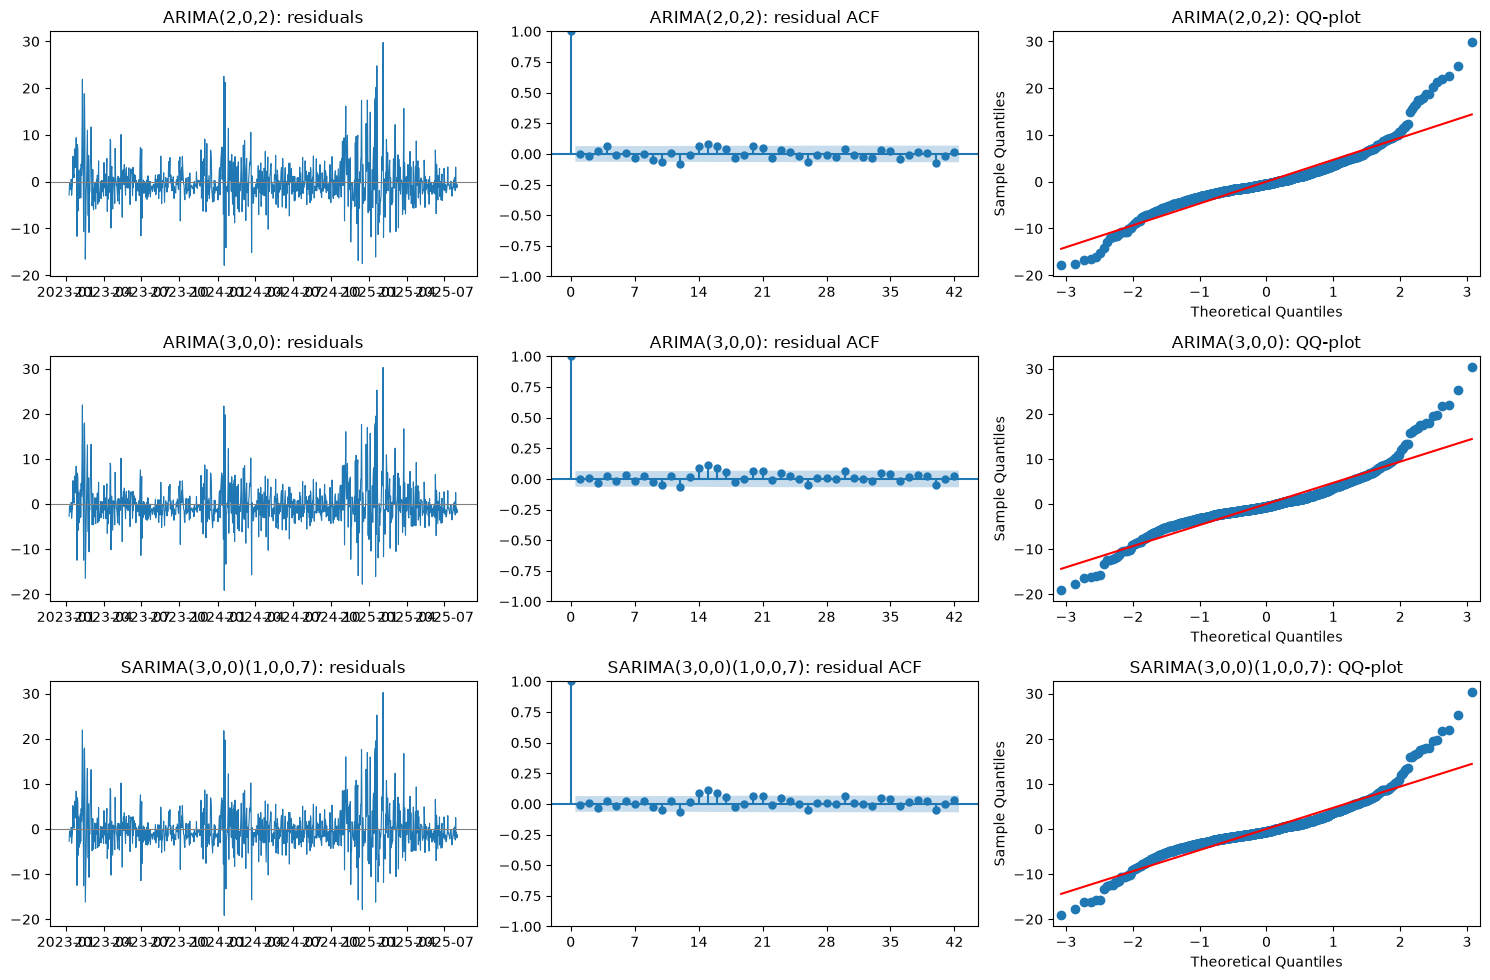

In [7]:
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import jarque_bera

final_models = {
    "ARIMA(2,0,2)": ((2, 0, 2), (0, 0, 0, 0)),
    "ARIMA(3,0,0)": ((3, 0, 0), (0, 0, 0, 0)),
    "SARIMA(3,0,0)(1,0,0,7)": ((3, 0, 0), (1, 0, 0, 7)),
}

final_fits = {}
for name, (order, seasonal_order) in final_models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        final_fits[name] = SARIMAX(
            train, order=order, seasonal_order=seasonal_order, trend="c"
        ).fit(disp=False, maxiter=200)

# Summary table
rows = []
for name, res in final_fits.items():
    order, seasonal_order = final_models[name]
    model_df = order[0] + order[2] + seasonal_order[0] + seasonal_order[2]
    resid = res.resid.iloc[7:]  # same convention as the grid
    lb = acorr_ljungbox(resid, lags=[14, 28], model_df=model_df)
    jb_stat, jb_p, skew, kurt = jarque_bera(resid)
    rows.append(
        {
            "model": name,
            "AIC": round(res.aic, 1),
            "BIC": round(res.bic, 1),
            "LB p@14": round(lb.loc[14, "lb_pvalue"], 3),
            "LB p@28": round(lb.loc[28, "lb_pvalue"], 3),
            "JB p": round(jb_p, 4),
            "skew": round(skew, 2),
            "kurtosis": round(kurt, 2),
            "resid std": round(resid.std(), 2),
        }
    )
display(pd.DataFrame(rows).set_index("model"))

# Residual diagnostics: time plot, ACF, QQ-plot
fig, axes = plt.subplots(len(final_fits), 3, figsize=(15, 3.3 * len(final_fits)))
for i, (name, res) in enumerate(final_fits.items()):
    resid = res.resid.iloc[7:]
    axes[i, 0].plot(resid.index, resid.values, linewidth=0.8)
    axes[i, 0].axhline(0, color="gray", linewidth=0.8)
    axes[i, 0].set_title(f"{name}: residuals")
    plot_acf(resid, lags=42, ax=axes[i, 1])
    axes[i, 1].set_title(f"{name}: residual ACF")
    axes[i, 1].set_xticks(range(0, 43, 7))
    qqplot(resid, line="s", ax=axes[i, 2])
    axes[i, 2].set_title(f"{name}: QQ-plot")
fig.tight_layout()
save_current_figure("03_sarima_residual_diagnostics.png")
plt.show()

## 7. Forecast on the test set and baselines

90-day-ahead forecasts from the end of the training set, compared with four baselines (train mean, last value, seasonal naive 7d and 365d). The ARIMA forecast converges to the long-run mean after about two weeks, and its 95% interval is unrealistic (it goes below zero).

,RMSE,MAE,AIC,BIC
model,,,,
Baseline: seasonal naive (7d),4.172,3.178,NaN,NaN
"ARIMA(2,0,2)",4.185,3.622,5598.7,5627.8
Baseline: naive (last value),4.275,2.969,NaN,NaN
"ARIMA(3,0,0)",4.894,4.367,5602.5,5626.8
"SARIMA(3,0,0)(1,0,0,7)",4.895,4.368,5604.3,5633.4
Baseline: train mean,5.048,4.571,NaN,NaN
Baseline: seasonal naive (365d),6.076,4.843,NaN,NaN


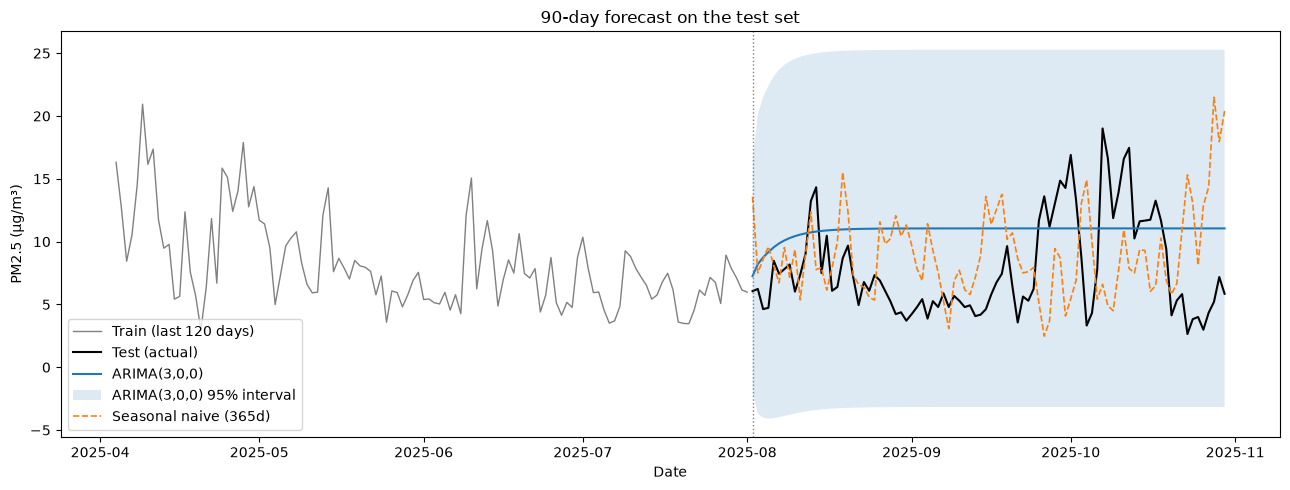

In [8]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def mae(y_true, y_pred) -> float:
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


forecasts = {}   # name -> pd.Series aligned on test.index
results = []     # rows for the final comparison table


def evaluate(name, y_pred, aic=np.nan, bic=np.nan):
    y_pred = pd.Series(np.asarray(y_pred), index=test.index, name=name)
    forecasts[name] = y_pred
    results.append(
        {
            "model": name,
            "RMSE": round(rmse(test, y_pred), 3),
            "MAE": round(mae(test, y_pred), 3),
            "AIC": aic,
            "BIC": bic,
        }
    )


# --- ARIMA / SARIMA: 90-step-ahead forecasts from the end of the train set ---
conf_ints = {}
for name, res in final_fits.items():
    fc = res.get_forecast(steps=len(test))
    assert fc.predicted_mean.index.equals(test.index), "forecast index mismatch"
    evaluate(name, fc.predicted_mean.values, aic=round(res.aic, 1), bic=round(res.bic, 1))
    conf_ints[name] = fc.conf_int(alpha=0.05)

# --- Baselines ---
evaluate("Baseline: train mean", np.full(len(test), train.mean()))
evaluate("Baseline: naive (last value)", np.full(len(test), train.iloc[-1]))
evaluate("Baseline: seasonal naive (7d)", np.tile(train.iloc[-7:].values, len(test) // 7 + 1)[: len(test)])
evaluate(
    "Baseline: seasonal naive (365d)",
    train.reindex(test.index - pd.Timedelta(days=365)).values,
)

metrics_table = pd.DataFrame(results).set_index("model").sort_values("RMSE")
display(metrics_table)

# --- Plot: last 120 train days + test actuals + forecasts ---
MAIN = "ARIMA(3,0,0)"
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.index[-120:], train.values[-120:], color="gray", linewidth=1, label="Train (last 120 days)")
ax.plot(test.index, test.values, color="black", linewidth=1.5, label="Test (actual)")
ax.plot(forecasts[MAIN].index, forecasts[MAIN].values, linewidth=1.5, label=MAIN)
ax.fill_between(
    test.index, conf_ints[MAIN].iloc[:, 0], conf_ints[MAIN].iloc[:, 1],
    alpha=0.15, label=f"{MAIN} 95% interval",
)
ax.plot(forecasts["Baseline: seasonal naive (365d)"].index,
        forecasts["Baseline: seasonal naive (365d)"].values,
        linestyle="--", linewidth=1.2, label="Seasonal naive (365d)")
ax.axvline(test.index[0], color="gray", linestyle=":", linewidth=1)
ax.set_title("90-day forecast on the test set")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Date")
ax.legend()
fig.tight_layout()
save_current_figure("03_arima_forecast_vs_actual.png")
plt.show()

## 8. Prophet

Weekly + yearly seasonality + French holidays, fitted on the training set, in additive and multiplicative mode. Components: strong yearly cycle, small weekly effect, noisy holiday effects (2-3 occurrences each). Neither mode clearly beats the baselines on the test window.

Importing plotly failed. Interactive plots will not work.
01:23:17 - cmdstanpy - INFO - Chain [1] start processing
01:23:17 - cmdstanpy - INFO - Chain [1] done processing
01:23:17 - cmdstanpy - INFO - Chain [1] start processing
01:23:18 - cmdstanpy - INFO - Chain [1] done processing


,RMSE,MAE,AIC,BIC
model,,,,
Baseline: seasonal naive (7d),4.172,3.178,NaN,NaN
"ARIMA(2,0,2)",4.185,3.622,5598.7,5627.8
Prophet (additive),4.239,3.426,NaN,NaN
Baseline: naive (last value),4.275,2.969,NaN,NaN
Prophet (multiplicative),4.420,3.638,NaN,NaN
"ARIMA(3,0,0)",4.894,4.367,5602.5,5626.8
"SARIMA(3,0,0)(1,0,0,7)",4.895,4.368,5604.3,5633.4
Baseline: train mean,5.048,4.571,NaN,NaN
Baseline: seasonal naive (365d),6.076,4.843,NaN,NaN


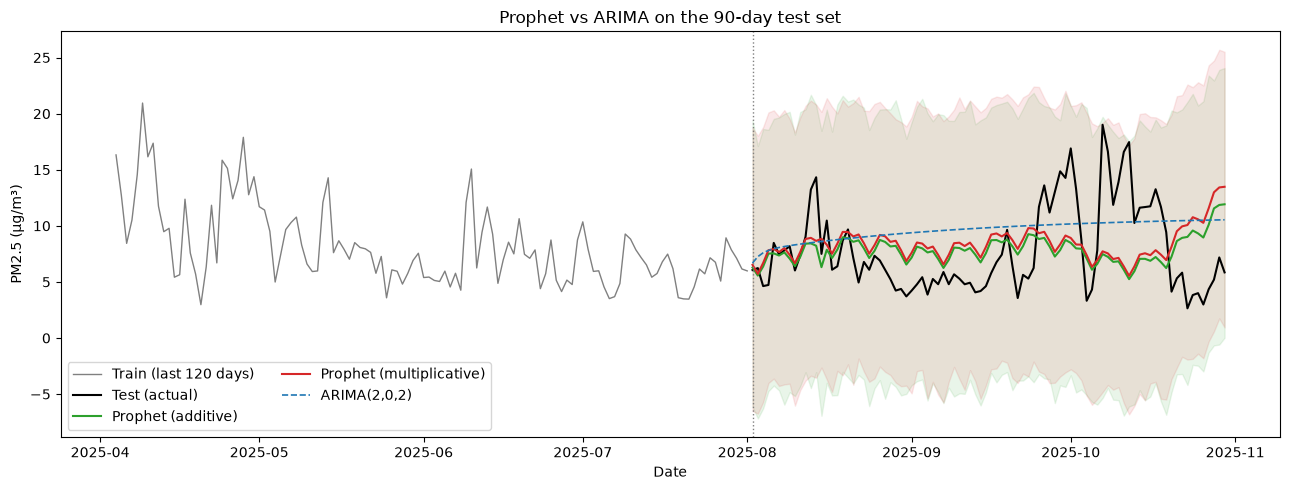

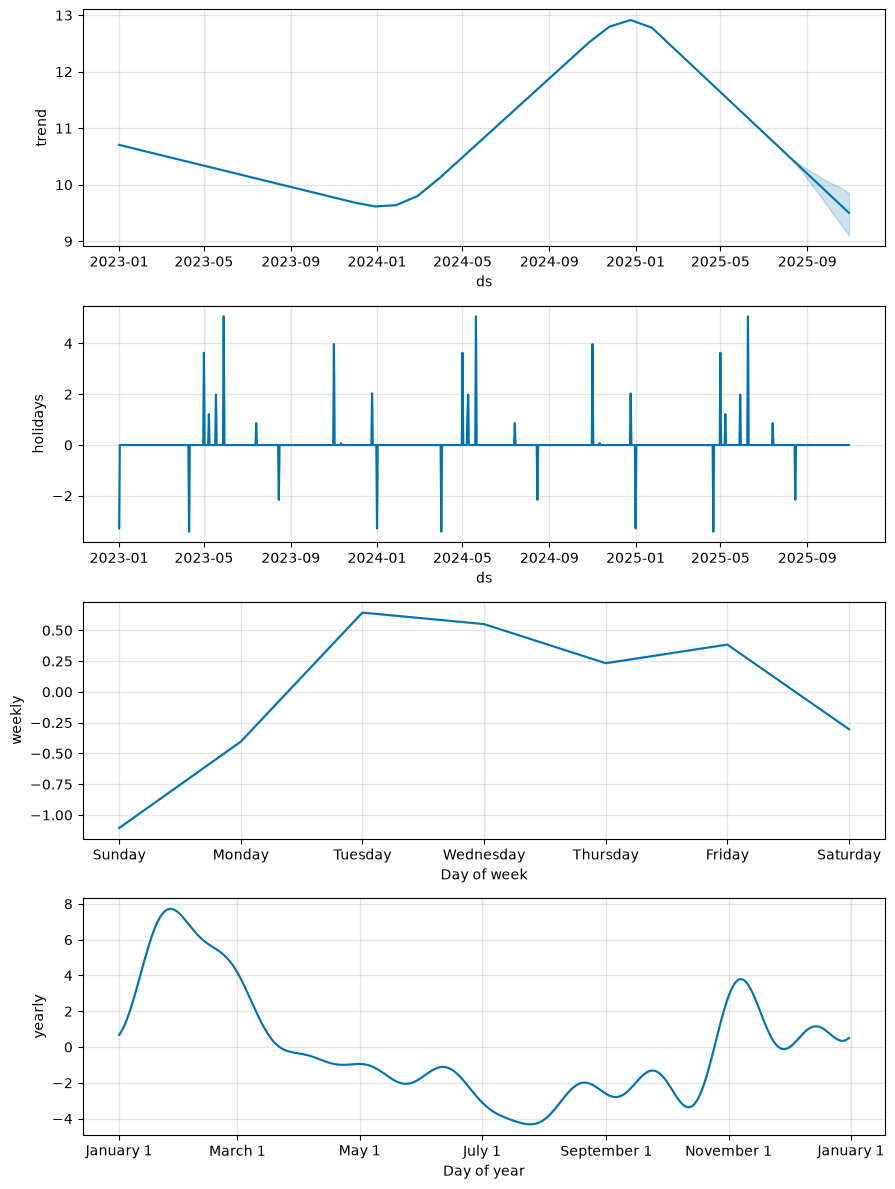

In [9]:
import logging

from prophet import Prophet

logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

train_df = train.rename_axis("ds").reset_index(name="y")
all_dates = pd.DataFrame({"ds": series.index})

prophet_models = {}
prophet_fc = {}

for mode in ["additive", "multiplicative"]:
    m = Prophet(
        seasonality_mode=mode,
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        interval_width=0.95,
    )
    m.add_country_holidays(country_name="FR")
    m.fit(train_df)

    fc_all = m.predict(all_dates).set_index("ds")
    prophet_models[mode] = m
    prophet_fc[mode] = fc_all

    name = f"Prophet ({mode})"
    evaluate(name, fc_all.loc[test.index, "yhat"].values)

metrics_table = pd.DataFrame(results).set_index("model").sort_values("RMSE")
display(metrics_table)

# --- Plot: Prophet forecasts vs actual on the test period ---
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.index[-120:], train.values[-120:], color="gray", linewidth=1, label="Train (last 120 days)")
ax.plot(test.index, test.values, color="black", linewidth=1.5, label="Test (actual)")
for mode, color in [("additive", "tab:green"), ("multiplicative", "tab:red")]:
    fc = prophet_fc[mode].loc[test.index]
    ax.plot(test.index, fc["yhat"], color=color, linewidth=1.5, label=f"Prophet ({mode})")
    ax.fill_between(test.index, fc["yhat_lower"], fc["yhat_upper"], color=color, alpha=0.10)
ax.plot(forecasts["ARIMA(2,0,2)"].index, forecasts["ARIMA(2,0,2)"].values,
        color="tab:blue", linestyle="--", linewidth=1.2, label="ARIMA(2,0,2)")
ax.axvline(test.index[0], color="gray", linestyle=":", linewidth=1)
ax.set_title("Prophet vs ARIMA on the 90-day test set")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Date")
ax.legend(ncol=2)
fig.tight_layout()
save_current_figure("03_prophet_forecast_vs_actual.png")
plt.show()

# --- Prophet components (additive model): trend, holidays, weekly, yearly ---
fig_c = prophet_models["additive"].plot_components(prophet_fc["additive"].reset_index())
save_current_figure("03_prophet_components.png")
plt.show()

## 9. Rolling-origin evaluation (4 consecutive 90-day windows)

A single 90-day window is too noisy to rank models, so four consecutive windows with an expanding training set are used. A regularized Prophet (yearly Fourier order 4, `holidays_prior_scale = 1`) is added, with settings fixed before looking at these results. The last fold is the original test split.

In [10]:
N_FOLDS = 4
HORIZON = TEST_DAYS  # 90-day windows, same horizon as the main split


def arima_forecast(train_fold, order, steps):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = SARIMAX(train_fold, order=order, trend="c").fit(disp=False, maxiter=200)
    return res.get_forecast(steps=steps).predicted_mean.values


def prophet_forecast(train_fold, future_index, **kwargs):
    params = dict(
        seasonality_mode="additive",
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
    )
    params.update(kwargs)
    model = Prophet(**params)
    model.add_country_holidays(country_name="FR")
    model.fit(train_fold.rename_axis("ds").reset_index(name="y"))
    return model.predict(pd.DataFrame({"ds": future_index}))["yhat"].values


rows = []
windows = {}
t0 = time.time()
for fold, offset in enumerate(range(N_FOLDS - 1, -1, -1), start=1):
    end = len(series) - offset * HORIZON
    start = end - HORIZON
    tr, te = series.iloc[:start], series.iloc[start:end]
    windows[fold] = f"{te.index[0].date()} -> {te.index[-1].date()} (train: {len(tr)} days)"

    preds = {
        "ARIMA(2,0,2)": arima_forecast(tr, (2, 0, 2), HORIZON),
        "ARIMA(3,0,0)": arima_forecast(tr, (3, 0, 0), HORIZON),
        "Prophet (additive)": prophet_forecast(tr, te.index),
        "Prophet (regularized)": prophet_forecast(
            tr, te.index, yearly_seasonality=4, holidays_prior_scale=1.0
        ),
        "Baseline: train mean": np.full(HORIZON, tr.mean()),
        "Baseline: naive (last value)": np.full(HORIZON, tr.iloc[-1]),
        "Baseline: seasonal naive (7d)": np.tile(tr.iloc[-7:].values, HORIZON // 7 + 1)[:HORIZON],
    }
    for name, pred in preds.items():
        rows.append({"fold": fold, "model": name, "RMSE": rmse(te, pred), "MAE": mae(te, pred)})
    print(f"fold {fold}/{N_FOLDS} done ({time.time() - t0:.0f}s)")

print("\nTest windows:")
for fold, w in windows.items():
    print(f"  fold {fold}: {w}")

cv = pd.DataFrame(rows)
for metric in ["RMSE", "MAE"]:
    table = cv.pivot(index="model", columns="fold", values=metric)
    table["mean"] = table.mean(axis=1)
    print(f"\n=== {metric} per fold ===")
    display(table.sort_values("mean").round(2))

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
01:26:23 - cmdstanpy - INFO - Chain [1] start processing
01:26:23 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
01:26:23 - cmdstanpy - INFO - Chain [1] start processing
01:26:23 - cmdstanpy - INFO - Chain [1] done processing


fold 1/4 done (2s)


01:26:27 - cmdstanpy - INFO - Chain [1] start processing
01:26:27 - cmdstanpy - INFO - Chain [1] done processing
01:26:27 - cmdstanpy - INFO - Chain [1] start processing
01:26:27 - cmdstanpy - INFO - Chain [1] done processing


fold 2/4 done (7s)


01:26:30 - cmdstanpy - INFO - Chain [1] start processing
01:26:30 - cmdstanpy - INFO - Chain [1] done processing
01:26:31 - cmdstanpy - INFO - Chain [1] start processing
01:26:31 - cmdstanpy - INFO - Chain [1] done processing


fold 3/4 done (10s)


01:26:34 - cmdstanpy - INFO - Chain [1] start processing
01:26:34 - cmdstanpy - INFO - Chain [1] done processing
01:26:34 - cmdstanpy - INFO - Chain [1] start processing
01:26:34 - cmdstanpy - INFO - Chain [1] done processing


fold 4/4 done (13s)

Test windows:
  fold 1: 2024-11-05 -> 2025-02-02 (train: 674 days)
  fold 2: 2025-02-03 -> 2025-05-03 (train: 764 days)
  fold 3: 2025-05-04 -> 2025-08-01 (train: 854 days)
  fold 4: 2025-08-02 -> 2025-10-30 (train: 944 days)

=== RMSE per fold ===


fold,1,2,3,4,mean
model,,,,,
"ARIMA(2,0,2)",12.89,7.65,5.08,4.19,7.45
"ARIMA(3,0,0)",13.15,7.69,5.04,4.89,7.69
Prophet (regularized),12.82,7.42,7.99,3.78,8.00
Prophet (additive),13.28,7.57,7.76,4.24,8.21
Baseline: train mean,13.90,8.90,5.10,5.05,8.24
Baseline: naive (last value),14.82,15.47,3.43,4.27,9.50
Baseline: seasonal naive (7d),14.00,13.53,7.08,4.17,9.69



=== MAE per fold ===


fold,1,2,3,4,mean
model,,,,,
"ARIMA(2,0,2)",9.72,5.38,4.69,3.62,5.85
"ARIMA(3,0,0)",9.81,5.39,4.64,4.37,6.05
Baseline: train mean,10.32,5.93,4.72,4.57,6.39
Prophet (regularized),9.99,5.46,7.69,2.94,6.52
Prophet (additive),10.41,5.52,7.43,3.43,6.70
Baseline: seasonal naive (7d),12.04,10.55,6.24,3.18,8.00
Baseline: naive (last value),12.96,14.37,3.04,2.97,8.33


## 10. Final comparison

Test-window metrics and rolling-origin means in one table, saved to `reports/tables/`. SARIMA, Prophet (multiplicative) and the 365d seasonal naive were evaluated on the main split only.

01:29:20 - cmdstanpy - INFO - Chain [1] start processing
01:29:20 - cmdstanpy - INFO - Chain [1] done processing


,Test RMSE,Test MAE,AIC,BIC,CV mean RMSE,CV mean MAE
model,,,,,,
"ARIMA(2,0,2)",4.185,3.622,5598.7,5627.8,7.449,5.852
"ARIMA(3,0,0)",4.894,4.367,5602.5,5626.8,7.692,6.053
Prophet (regularized),3.781,2.941,NaN,NaN,8.003,6.519
Prophet (additive),4.239,3.426,NaN,NaN,8.212,6.695
Baseline: train mean,5.048,4.571,NaN,NaN,8.237,6.387
Baseline: naive (last value),4.275,2.969,NaN,NaN,9.501,8.332
Baseline: seasonal naive (7d),4.172,3.178,NaN,NaN,9.694,8.002
"SARIMA(3,0,0)(1,0,0,7)",4.895,4.368,5604.3,5633.4,NaN,NaN
Baseline: seasonal naive (365d),6.076,4.843,NaN,NaN,NaN,NaN


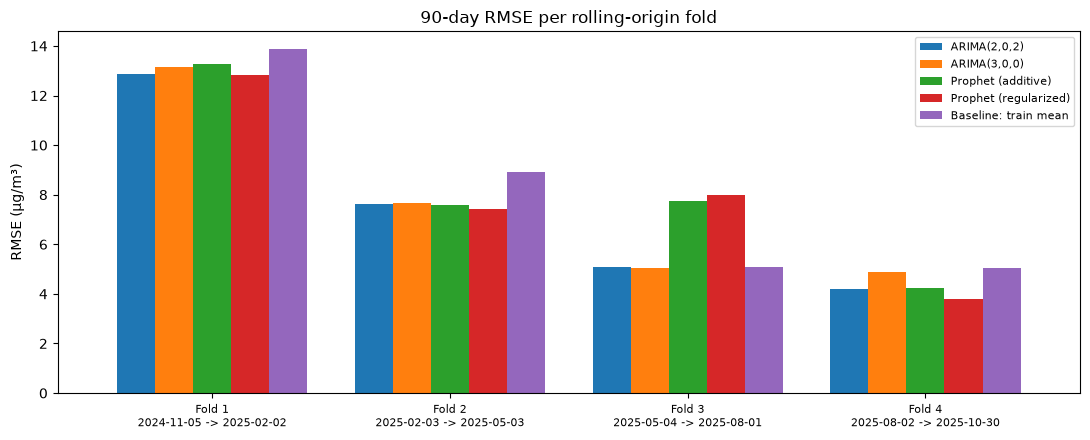

In [11]:
# --- Add the regularized Prophet to the main-split results (same as fold 4) ---
name = "Prophet (regularized)"
results[:] = [r for r in results if r["model"] != name]  # idempotent if re-run
evaluate(
    name,
    prophet_forecast(train, test.index, yearly_seasonality=4, holidays_prior_scale=1.0),
)

# --- Final table ---
main_table = pd.DataFrame(results).set_index("model")
cv_mean = cv.groupby("model")[["RMSE", "MAE"]].mean().add_prefix("CV mean ")

final_table = (
    main_table.rename(columns={"RMSE": "Test RMSE", "MAE": "Test MAE"})
    .join(cv_mean)
    .sort_values("CV mean RMSE")
    .round(3)
)
display(final_table)

# --- Save tables for the report / pull request ---
tables_dir = project_root / "reports/tables"
tables_dir.mkdir(parents=True, exist_ok=True)
final_table.to_csv(tables_dir / "03_forecasting_metrics.csv")
cv.round(4).to_csv(tables_dir / "03_forecasting_cv_folds.csv", index=False)

# --- Chart: RMSE per fold for the main models ---
plot_models = [
    "ARIMA(2,0,2)", "ARIMA(3,0,0)",
    "Prophet (additive)", "Prophet (regularized)",
    "Baseline: train mean",
]
pivot = cv[cv["model"].isin(plot_models)].pivot(index="fold", columns="model", values="RMSE")[plot_models]
ax = pivot.plot(kind="bar", figsize=(11, 4.5), width=0.8)
ax.set_xticklabels(
    [f"Fold {f}\n{windows[f].split(' (')[0]}" for f in pivot.index], rotation=0, fontsize=8
)
ax.set_xlabel("")
ax.set_ylabel("RMSE (µg/m³)")
ax.set_title("90-day RMSE per rolling-origin fold")
ax.legend(fontsize=8)
ax.figure.tight_layout()
save_current_figure("03_cv_rmse_per_fold.png")
plt.show()

## Interpretation and conclusions

### Stationarity and model order
- ADF and KPSS agree that the raw training series is stationary (ADF p = 0.0006, KPSS p ≥ 0.10), so `d = 0`. Differencing the series (`d = 1` and/or `D = 1`) is not needed.
- The weekly cycle is weak: lag-7 autocorrelation is about 0.21, and day-of-week means differ by only about 1.8 µg/m³ (Prophet's weekly component). A seasonal difference at lag 7 over-differences the series: the residual ACF shows a spike of about -0.54 at lag 7, and the seasonal MA coefficient of the fitted `D = 1` models went to about -1 (non-invertible). Those models were discarded, even though their AIC looked better in an unconstrained grid.
- With stationarity and invertibility enforced, the best models have no seasonal terms (AIC selects ARIMA(2,0,2), BIC selects ARIMA(3,0,0)). Adding a weekly seasonal AR term does not improve AIC/BIC or the forecasts, so **ARIMA is preferred over SARIMA** for this series. SARIMA(3,0,0)(1,0,0,7) is kept in the comparison to document that choice.

### ARIMA diagnostics
- Short-term dynamics are captured: the residual ACF is inside the confidence bands for lags 1-13.
- Remaining issues: Ljung-Box still rejects at lag 28 (p ≤ 0.002 for all models), reflecting slow structure a non-seasonal ARMA cannot model, and the residuals are heteroscedastic and heavy-tailed (skew ≈ 1.0, kurtosis ≈ 9, Jarque-Bera p ≈ 0), with much larger swings in winter than in summer.
- Consequences: point forecasts are usable, but prediction intervals are unreliable. The 95% interval is the same width in all seasons and goes below zero, which is impossible for PM2.5. A log transform would be the natural next step (not done here).
- A stationary ARMA forecasting 90 days ahead converges to the long-run mean within about two weeks, so over this horizon it is essentially a mean forecast.

### Prophet
- Components: a strong yearly cycle (peak in February, trough in July, roughly 12 µg/m³ peak-to-trough), a small weekly effect (Sunday lowest, Tuesday highest), and a trend that rises and then falls over 2023-2025. With under three years of data, trend and yearly seasonality cannot be cleanly separated.
- French holiday effects are estimated from only 2-3 occurrences each, with inconsistent signs, and should be treated as noise rather than as findings.
- The default yearly seasonality (Fourier order 10) looks overfitted. A pre-declared, more regularized version (yearly order 4, `holidays_prior_scale = 1`) was therefore also evaluated.

### Model comparison
- On the fixed 90-day test window (2025-08-02 to 2025-10-30), Prophet (regularized) has the lowest RMSE (3.78) and ARIMA(2,0,2) is the best ARIMA (4.19). However, simple baselines (seasonal naive 7d: 4.17, naive: 4.28) are in the same range, so this single window does not separate the models.
- A rolling-origin evaluation (four consecutive 90-day windows, expanding training set) gives a more reliable picture. Mean RMSE: ARIMA(2,0,2) 7.45, ARIMA(3,0,0) 7.69, Prophet (regularized) 8.00, Prophet (additive) 8.21, train-mean baseline 8.24.
- Fold-to-fold variation is much larger than the differences between models. Winter 2024-25 is hard for every model (RMSE of about 13), since pollution episodes are not predictable from past values alone.
- Prophet does well when the level is low and stable (last fold), but is clearly worse than ARIMA in May-August 2025 (RMSE of about 8 vs 5). A plausible explanation is trend extrapolation during the seasonal transition, but we have not verified it.
- Regularizing Prophet helped in 3 of 4 folds, with a modest mean RMSE gain of about 0.2.
- **Overall:** ARIMA(2,0,2) is the most consistent model, Prophet (regularized) is competitive on some windows, and neither beats a long-run-mean baseline by more than about 10% at this horizon.

### Limitations
- Only four overlapping evaluation windows, and a single sensor/city.
- ARIMA orders were selected by AIC/BIC on the training set only. The Prophet variants were declared before looking at the rolling-origin results, but the test windows were used to compare models, so the reported errors are not fully independent of the model choice.
- SARIMA, Prophet (multiplicative) and the 365-day seasonal naive were evaluated only on the main split.
- No exogenous variables (weather, traffic) and no variance-stabilizing transform.
- Prediction intervals are unreliable (negative lower bounds, constant width across seasons).